**imports**
- sys.path is the list of folders where Python looks for modules
- The notebook runs from within the `notebooks/` directory, and `src/` is one level up (`..`), so that folder needs to be added.

In [1]:
import sys
sys.path.append("..")          # the notebook runs inside notebooks/; this lets Python find src/

import numpy as np
import pandas as pd
from src.cashflow import load_constants
from src.cashflow import run_trajectory
from src.bootstrap import block_bootstrap
from src.bootstrap import summarize_trajectory
from src.bootstrap import simulate

%load_ext autoreload
%autoreload 2

pd.set_option("display.float_format", "{:,.4f}".format)

N_SIMS=10_000


**Comparison: real vs theoretical autocorrelation**
- Real autocorrelation: e_base.autocorr(lag=k)
- theoretical autocorrelation: 0.64 ** k

In [2]:
#1. Upload csv file
df = pd.read_csv(r"../data/processed/annual_energy.csv")
e_base = df ['energy_base_gwh']

#2. Create the list with rows in 'for' loop
rows = []
for k in range(1, 9):
    rows.append({
        "lag": k, 
        "real": e_base.autocorr(lag=k),
        "ar1": 0.64 ** k})

#3. Create and show dataframe
acf = pd.DataFrame(rows)
acf

,lag,real,ar1
0,1,0.6445,0.6400
1,2,0.4662,0.4096
2,3,0.3525,0.2621
3,4,0.3216,0.1678
4,5,0.2534,0.1074
5,6,0.2408,0.0687
6,7,0.2138,0.0440
7,8,0.2083,0.0281


**Interpretation**:
- The “each year depends only on the previous one” model underestimates the river’s memory. When accounting for actual autocorrelation, the drop below 0.236 does not occur until 6 to 7 years later, not at 3 or 4 years. The river possesses a slow, multi-year component that the 0.64^k term fails to capture.

**Choosing the new L value**:
We need to consider that:
- The 0.236 band is thinner than it looks.
- There is a third, automatic criterion, which is the standard one. The Politis and White method estimates the optimal block length directly from the series.

In [3]:
from arch.bootstrap import optimal_block_length
optimal_block_length(df['energy_base_gwh'])


,stationary,circular
energy_base_gwh,6.9792,7.9891


**Result summary to choose L**
| Method | Suggested L | Observation |
| :--- | :---: | :---: |
| n^(1/3) | 4   | This method does not have any constant that depends of the data serie |
| Actual autocorrelation vs. band | 6 - 7 | The band is not that precise |
| Politis-White (circular) | 8 | Published method, automatic, without estimated ranges |

**Simulate function for Base case**

In [4]:
semi = pd.read_csv("../data/processed/semiannual_energy.csv")
table = semi.pivot(index="hydro_year", columns="half", values="energy_base_gwh").to_numpy()

# Parameters
n_records = table.shape[0]                           # (69, 2): one row per hydrological year, columns S1 and S2
n_years = 30 
L=8 

# Random number generator
rng = np.random.default_rng(seed=42)

# Run a complete trajectory
    # Positions
positions = block_bootstrap(n_records, n_years, L, rng)
    # Extract the sorted rows
sorted_years_table = table[positions]
    # flatten row pwe row to obtain the cronological serie of 60 semesters
energy_trajectory = sorted_years_table.ravel()

# Execute funtion run_trajectory
c_base = load_constants("../model/hydro_pf_model_v1.xlsx")
result = run_trajectory(energy_trajectory, c_base )

print("BASE CASE WITH L=8:")
print(f"Table extracted per year: {sorted_years_table.shape}")  # Should be (30, 2)
print(f"Length of the final energy vector: {len(energy_trajectory)}")  # Should be 60
print("\nFirst 6 values of the vector (S1 year  1, S2 year 1, S1 year 2...):")
print(energy_trajectory[:6])

print(f"Minimum DSCR (12m) = ",(result["dscr_12m"][c_base["repayment_flag"] == 1].min()))
print(f"Equity IRR = " , result["equity_irr"])
print(f"Quantity of lockups = ", result["lockup"].sum())
print(f"Quantity of defaults = ", result["default"].sum())

BASE CASE WITH L=8:
Table extracted per year: (30, 2)
Length of the final energy vector: 60

First 6 values of the vector (S1 year  1, S2 year 1, S1 year 2...):
[34.72624783 14.31234707 33.77413039 18.37214137 29.34512023 14.35140804]
Minimum DSCR (12m) =  0.775677637420131
Equity IRR =  0.03045651571905328
Quantity of lockups =  2.0
Quantity of defaults =  2.0


In [5]:

sims = simulate(table, c_base, N_SIMS, 8, np.random.default_rng(42))
sims.mean()

min_dscr_12m            1.1770
any_lockup              0.5762
lockup_semesters        1.2691
any_default             0.2444
dsra_depleted           0.0997
sponsor_support     2,627.8906
equity_irr              0.0308
longest_dry_run         4.0450
min_annual_energy      42.7305
dtype: float64

**Simulate function for Tariff = 100.77 case**

In [6]:
# --------------- tariff100_p90 CASE ------------------
# Execute funtion run_trajectory
c_100 = load_constants("../tests/fixtures/tariff100_p90.xlsx")
result = run_trajectory(energy_trajectory, c_100 )

print(f"Table extracted per year: {sorted_years_table.shape}")  # Should be (30, 2)
print(f"Length of the final energy vector: {len(energy_trajectory)}")  # Should be 60
print("\nFirst 6 values of the vector (S1 year  1, S2 year 1, S1 year 2...):")
print(energy_trajectory[:6])

print(f"Minimum DSCR (12m) = ",(result["dscr_12m"][c_100["repayment_flag"] == 1].min()))
print(f"Equity IRR = " , result["equity_irr"])
print(f"Quantity of lockups = ", result["lockup"].sum())
print(f"Quantity of defaults = ", result["default"].sum())

print("CASE WITH TARIFF = 100.77 AND L=8:")
sims_100 = simulate(table, c_100, N_SIMS, 8, np.random.default_rng(42))
sims_100.mean()

Table extracted per year: (30, 2)
Length of the final energy vector: 60

First 6 values of the vector (S1 year  1, S2 year 1, S1 year 2...):
[34.72624783 14.31234707 33.77413039 18.37214137 29.34512023 14.35140804]
Minimum DSCR (12m) =  0.9097530365619614
Equity IRR =  0.0777673413184432
Quantity of lockups =  3.0
Quantity of defaults =  2.0
CASE WITH TARIFF = 100.77 AND L=8:


min_dscr_12m         1.1537
any_lockup           0.6090
lockup_semesters     1.3537
any_default          0.3632
dsra_depleted        0.0149
sponsor_support      0.0000
equity_irr           0.0835
longest_dry_run      4.0450
min_annual_energy   42.7305
dtype: float64

**Interpretation**:
- In a "wet" year (a year with high precipitation/inflow), tax losses (carryforwards) are utilized more rapidly. The issue lies in the timing of tax payments: due to the FIFO (first-in, first-out) methodology, these tax losses are applied to offset taxes well before year 11, having been consumed earlier during the "wet" year. Consequently, from year 11 onwards, the project no longer has any tax credits (losses) available to offset taxes, forcing it to make tax payments. This reduces the CFADS (Cash Flow Available for Debt Service) and lowers the DSCR (Debt Service Coverage Ratio). Thus, while the project may generate significantly more total profit over its entire 30 year lifespan, a period-by-period analysis reveals these timing-related challenges.

**To measure the weight of the effect**:
- Another dictionary, 'c_notax', will be created in which the tax rate constant is disabled, changing it from 'tax_rate' = 0.35 to 'tax_rate' = 0.0.

In [7]:
c_100 = load_constants("../tests/fixtures/tariff100_p90.xlsx")

c_notax = dict(c_100)          # copy of the dictionary
c_notax["tax_rate"] = 0.0      # only this key changes; c_100 stays as it was

sims_notax = simulate(table, c_notax, N_SIMS, 8, np.random.default_rng(42))
print("CASE WITH TARIFF = 100.77 AND NO TAX L=8:")
sims_notax.mean()

CASE WITH TARIFF = 100.77 AND NO TAX L=8:


min_dscr_12m          1.2519
any_lockup            0.3978
lockup_semesters      0.7211
any_default           0.2055
dsra_depleted         0.0149
sponsor_support     673.5106
equity_irr            0.1084
longest_dry_run       4.0450
min_annual_energy    42.7305
dtype: float64

**Interpretation**:
- It can be observed that the `any_default` rate is 21.3%, as detailed below. This confirms the effect of the tax-payment timing phenomenon we noted: with a 35% income tax, the probability of default at 100.77 USD/MWh is higher than in the base case (37.2% vs. 26.0%), whereas with taxes disabled, the probability of default is lower: 21.3% vs. 26.0%.
- It is important to note here that eliminating the taxes not only resolves the issue regarding the timing of tax payments, but the project also avoids paying the small amount of tax that the "sculpting" process had already accounted for; consequently, the project ends up with more cash on hand than the bank had projected.


Drought-related impact alone (excluding tax):    21.3%
Additional impact from tax timing:              + 15.9 percentage points
Total with 35% tax:                             37.2%


As a result, this gives us a double-edged interpretation:
- At a viable price point, the power plant withstands drought better (21% versus 26%), because fixed O&M costs have less of an impact.
- The repayment schedule structured for the P90 depends on when losses are incurred, and a "good" year can actually trigger a covenant breach years later. In practice, this is addressed through discussions with the bank (e.g., obtaining a waiver for the breach or restructuring the repayment schedule to provide more headroom).

**Hydrological scenario: recent period (2010–2025)**:
- The analysis of this case addresses the following question: if the climate conditions of the last 16 years were to persist, what level of risk would the loan (which was sized based on a 69-year period) carry?

- Next, it must be determined whether or not to change the value of L. Two perspectives can be considered:
    - Reducing the value of L, given that L=8 is quite large for a 16-year dataset (a criterion based on variety).
    - Maintaining the value of L, on the grounds that L represents the "memory" of the river—a characteristic that does not change simply because the time series does.
Neither alternative is superior to the other. In conclusion, a 16-year period is insufficient for a reliable bootstrap; therefore, this analysis of the recent period will be presented as a sensitivity test.

In [8]:
semi_recent = semi[semi["hydro_year"] >= 2010]
table_recent = semi_recent.pivot(index="hydro_year", columns="half", values="energy_base_gwh").to_numpy()
table_recent.shape      # should be (16, 2)

c_recent = load_constants("../model/hydro_pf_model_v1.xlsx")

# Simulate function with L=8
sims_recent_8 = simulate(table_recent, c_recent, N_SIMS, 8, np.random.default_rng(42))
print("RECENT CASE WITH L=8:")
print(sims_recent_8.mean())
print()
# Simulate function with L=4
sims_recent_4 = simulate(table_recent, c_recent, N_SIMS, 4, np.random.default_rng(42))
print("RECENT CASE WITH L=4: ")
print(sims_recent_4.mean())


RECENT CASE WITH L=8:
min_dscr_12m            1.1568
any_lockup              0.8120
lockup_semesters        1.6585
any_default             0.0000
dsra_depleted           0.1201
sponsor_support     6,581.9529
equity_irr              0.0193
longest_dry_run         3.4636
min_annual_energy      41.5902
dtype: float64

RECENT CASE WITH L=4: 
min_dscr_12m            1.1673
any_lockup              0.8045
lockup_semesters        1.6808
any_default             0.0000
dsra_depleted           0.1235
sponsor_support     6,680.1385
equity_irr              0.0192
longest_dry_run         3.3254
min_annual_energy      41.7982
dtype: float64


**Interpretation**:
- The recent period from 2010 to 2025 is mediocre, characterized by very low water flow, yet stable nonetheless. It is a period of "megadrought" where, despite the low flow rates, enough energy is still generated to avoid triggering a default.
- At 65 USD/MWh, the lock-up threshold occurs below approximately 42.8 GWh (95% of the P90 value), and the default threshold below approximately 40.5 GWh (90% of the P90 value). Three recent years fall within the "gray zone" (2011 at 42.5, 2020 at 42.0, and 2022 at 41.0), while none fall below 40.5. The two years from the full dataset that would have triggered a default—1969 (34.7) and 1971 (38.4), are not included in this sample.
- Warning: the fact that there hasn’t been an extreme year in 16 years does not prove that the recent climate is free of them.

- Final conclusion: a prolonged but moderate drought hinders dividend payouts (due to an 80% lock-up provision), while isolated extreme years lead to a default. This is a more nuanced version of H1.

**Hydrological scenario: E-FLOW 20%**:
- Now we analyze 20% e-flow scenario (as opposed to the base case, where e-flow = 10%) using its corresponding P90 debt figure (5.22 M). This approach assumes that the power plant is financed with the prior knowledge that the ecological flow will be 20% (rather than it changing at some point later). 

In [9]:

semi_20 = pd.read_csv("../data/processed/semiannual_energy.csv")
table_20 = semi_20.pivot(index="hydro_year", columns="half", values="energy_eco20_gwh").to_numpy()

c_20 = load_constants("../tests/fixtures/eco20_sized.xlsx")

# Simulate function with L=8
sims_20 = simulate(table_20, c_20, N_SIMS, 8, np.random.default_rng(42))
print("E-FLOW 20% CASE WITH L=8:")
print(sims_20.mean())
print()



E-FLOW 20% CASE WITH L=8:
min_dscr_12m              1.0437
any_lockup                0.6764
lockup_semesters          1.5675
any_default               0.6271
dsra_depleted             0.7644
sponsor_support     208,075.7729
equity_irr                0.0185
longest_dry_run           4.1327
min_annual_energy        33.2581
dtype: float64



**Interpretation**:
- To exemplify the mechanism:

||Normal year |  Dry year  | Dry / Normal|
|:---------| :-------- | :-------- |  :-------- |
|E-flow 10% (−4,4) |   25,6    |     15,6    |     61%|
|E-flow 20% (−8,8)  |   21,2    |     11,2    |     53%|

- First effect: it is a matter of proportion: with a 20% e-flow, a dry year ends up being proportionally further from the norm. Sculpting compensates for the level (by providing less water), but not for the dispersion.
- Second effect: In the Excel file, the semi-annual P90 for all cases is distributed according to the seasonal profile of the base case (65.7% from October to March). However, the actual 20% e-flow series shows 71% occurring from October to March, based on that same proportional mechanism. Thus, the debt repayment schedule anticipates a higher energy output during dry semesters than the river actually provides, and the DSRA is drawn upon during nearly every dry semester.

|E-flow 20% |Real serie| With the excel's profile |
|:---------| :-------- | :-------- |
|P(default) |   66.2%    |     66.1%   | 
|P(depleted DSRA) |  99.0%    |     78.9%    |
|Sponsor support |  1.328.545    |     180.417    |

- P(default) remains unchanged, because the covenant considers a 12-month period, and within a 12-month window, the distribution between semesters effectively cancels out.
- DSRA and sponsor support does change: this highlights the limitations of stage 2.

**Scenario: P50 with P50 sized debt:**

In [10]:
# Load constatn from fixture: p50_sized.xlsx
c_p50 = load_constants("../tests/fixtures/p50_sized.xlsx")

# Simulate function with L=8, with table from base case
sims_p50 = simulate(table, c_p50, N_SIMS, 8, np.random.default_rng(42))
print("P50 with P50 SIZED CASE WITH L=8:")
print(sims_p50.mean())
print()

P50 with P50 SIZED CASE WITH L=8:
min_dscr_12m             0.7927
any_lockup               0.9708
lockup_semesters         9.5118
any_default              0.9436
dsra_depleted            0.4229
sponsor_support     88,512.5140
equity_irr               0.0273
longest_dry_run          4.0450
min_annual_energy       42.7305
dtype: float64



**Results table:**

In [11]:
results = pd.DataFrame({
    "Base (65)": sims.mean(),
    "Tariff 100.77": sims_100.mean(),
    "Tariff 100.77, no tax": sims_notax.mean(),
    "Recent 2010-2025, L=8": sims_recent_8.mean(),
    "Recent 2010-2025, L=4": sims_recent_4.mean(),
    "E-flow 20%, own debt": sims_20.mean(),
    "Base, debt sized at P50": sims_p50.mean()

})
results.to_csv("../data/processed/montecarlo_results.csv")
results


,Base (65),Tariff 100.77,"Tariff 100.77, no tax","Recent 2010-2025, L=8","Recent 2010-2025, L=4","E-flow 20%, own debt","Base, debt sized at P50"
min_dscr_12m,1.1770,1.1537,1.2519,1.1568,1.1673,1.0437,0.7927
any_lockup,0.5762,0.6090,0.3978,0.8120,0.8045,0.6764,0.9708
lockup_semesters,1.2691,1.3537,0.7211,1.6585,1.6808,1.5675,9.5118
any_default,0.2444,0.3632,0.2055,0.0000,0.0000,0.6271,0.9436
dsra_depleted,0.0997,0.0149,0.0149,0.1201,0.1235,0.7644,0.4229
sponsor_support,"2,627.8906",0.0000,673.5106,"6,581.9529","6,680.1385","208,075.7729","88,512.5140"
equity_irr,0.0308,0.0835,0.1084,0.0193,0.0192,0.0185,0.0273
longest_dry_run,4.0450,4.0450,4.0450,3.4636,3.3254,4.1327,4.0450
min_annual_energy,42.7305,42.7305,42.7305,41.5902,41.7982,33.2581,42.7305


**Analysis of H3 and sensitivity of L**:
- Hypothesis H3: If the years are simulated as independent (L = 1), the risk is underestimated. In D30, it was predicted that this would be false for the P(default) and true for the DSRA and the sponsors. This is now being tested.
- We will run the base case (65 USD/MWh) with L = 1, 2, 4, 6, 8, 10, and 12, all using the same seed (shared random numbers),and create a table with one column for each L.
- In this analysis, we will make two runs: one for N=1000 and one for N=10000, in order to analyze the dispersion of the values comparing both N sims.


In [12]:
by_L = {}
for L in [1, 2, 4, 6, 8, 10, 12]:
    s = simulate(table, c_base, N_SIMS, L, np.random.default_rng(42)) # Sim with N=10000
    m = s.mean() # Average of each metric over the trajectories
    m["equity_irr_std"] = s["equity_irr"].std()
    by_L[f"L={L}"] = m
sens_L = pd.DataFrame(by_L)
sens_L

,L=1,L=2,L=4,L=6,L=8,L=10,L=12
min_dscr_12m,1.1577,1.1522,1.1781,1.1889,1.1770,1.1516,1.1664
any_lockup,0.6095,0.6224,0.5700,0.5448,0.5762,0.6276,0.6047
lockup_semesters,1.1506,1.2138,1.2522,1.2337,1.2691,1.3351,1.2741
any_default,0.3039,0.3140,0.2580,0.2334,0.2444,0.2746,0.2335
dsra_depleted,0.1004,0.0943,0.0986,0.1004,0.0997,0.1014,0.1028
sponsor_support,"5,292.1336","2,657.5668","2,823.6479","2,926.9626","2,627.8906","2,480.2005","2,119.7775"
equity_irr,0.0310,0.0310,0.0309,0.0307,0.0308,0.0307,0.0307
longest_dry_run,2.9903,3.5584,3.9263,4.1193,4.0450,3.9790,3.9645
min_annual_energy,41.7816,41.8204,42.4667,42.7922,42.7305,42.6594,42.9862
equity_irr_std,0.0039,0.0050,0.0061,0.0069,0.0074,0.0080,0.0080


**Interpretation:**
- Both metrics: DSRA depleted and Sponsor Support are limited to the loan term, because after maturity the CFADS may turn negative during dry periods (given a fixed price until year 20 and O&M costs escalating at 2%); this represents an operational risk for the sponsor, not the bank.
- Finding: the power plant loses money during the dry semesters of years 13 through 20.


Sem. 1 to 4 ---> Construction ---> There is no debt 

Sem. 5 to 28 ---> Debt (24 payments) ---> We consider this period, there is DSRA that protects the project

Sem. 29 to 64 ---> After paying the debt ---> Debt already payed, there is no DSRA

|Metric|L=1 (independent years)|L=8 (reference case)|Conclussion|
|:-----|:-----|:-----|:-----|
|P(default)|30.4%|24.4%| L=1 overestimates P(default) over 6 points|
|P(DSRA depleted)| 10.0%| 10.0%| No effect|
|Sponsor support|5,292 USD |2,627 USD | Practically no effect: very low USD contribution|
|Semesters in lockup| 1.15| 1.27| Rises 10%|
|Equity IRR standard deviation| 0.39% | 0.74%| L=1 underestimates it by half|

|Metric|L=4|L=12 |Conclussion|
|:-----|:-----|:-----|:-----|
|P(default)|25.8%|23.4%| L=12 is 2.4 points lower than L=4|


**Prove that the results are independent of N and the seed:**
- N test (law of large numbers): as N increases, the simulated average approaches the true value, and its standard error decreases at a rate of 1/√N.
- Seed test: N (the definitive value) is kept constant, and only the seed is changed. The question is whether the difference is on the order of the standard error (normal noise) or significantly larger (a bug).

In [13]:
# N test
conv_N = []
for N in [1000, 5000, 10000, 20000]: # For loop for diferent N values
    s = simulate(table, c_base, N, 8, np.random.default_rng(42))  # Sim case base with seed 42
    p = s["any_default"].mean()
    se = np.sqrt(p * (1-p)/N)         # standard error of a simulated probability
    conv_N.append({"N": N, "p_default": p, "se": se,"+-": 1.96*se, "ci_low": p - 1.96 * se, "ci_high": p + 1.96 * se})
pd.DataFrame(conv_N)

,N,p_default,se,+-,ci_low,ci_high
0,1000,0.2600,0.0139,0.0272,0.2328,0.2872
1,5000,0.2414,0.0061,0.0119,0.2295,0.2533
2,10000,0.2444,0.0043,0.0084,0.2360,0.2528
3,20000,0.2442,0.0030,0.0060,0.2383,0.2502


In [14]:
# Seed test
conv_seed = []
N_fixed=10000

# Fixed seeds 1 to 5 + the reference seed 42
seeds = [1,2,3,4,5,42]
print(f"Seeds: {seeds}")

for seed in seeds : # For loop with seed values [1,2,3,4,5,42]
    s = simulate(table, c_base, N_fixed , 8, np.random.default_rng(seed))  
    p = s["any_default"].mean()
    se = np.sqrt(p * (1-p)/N_fixed)         # standard error of a simulated probability
    conv_seed.append({"seed": seed,"N": N_fixed, "p_default": p, "se":se, "ci_low": p - 1.96 * se, "ci_high": p + 1.96 * se})
pd.DataFrame(conv_seed)



Seeds: [1, 2, 3, 4, 5, 42]


,seed,N,p_default,se,ci_low,ci_high
0,1,10000,0.2525,0.0043,0.2440,0.2610
1,2,10000,0.2444,0.0043,0.2360,0.2528
2,3,10000,0.2499,0.0043,0.2414,0.2584
3,4,10000,0.2412,0.0043,0.2328,0.2496
4,5,10000,0.2523,0.0043,0.2438,0.2608
5,42,10000,0.2444,0.0043,0.2360,0.2528


**H1 Analysis:**
- Hypothesis H1 states: Debt capacity is determined by dry years, particularly by sequences of several consecutive dry years. So, what is being sought is to determine whether the debt is determined by:
     - A sequence of dry years (consecutive bad years)
     - An extremely dry year (an isolated, extremely bad event)
- To answer this question, we will outline two approaches to determine the answer:

     - **First mechanism:** construct a 2x2 table for each trajectory, in which the following questions are addressed: Did the trajectory experience an extreme year? And did the trajectory have a long streak?. 
     Focusing specifically on years in which a default occurred—which are of the greatest importance to the bank, we are interested in the answers to two questions for those years; these will help us determine whether the defaults are triggered by a string of bad years or by specific, extreme, one-off events.
     - **Second mechanism:** Use Spearman's correlation, which operates based on ranks; therefore, it does not matter that the duration (the "streak") is measured in years, while the most critical year is expressed in GWh. The correlation of each measure with the minimum DSCR over the loan's trajectory is calculated, and the one with the strongest correlation (furthest from 0) is the one that best explains how poorly the loan performed.

Considerations:
- A year will be categorized as "extrem year" if their minimum annual energy is < 40.5
- A streak of dry years will be considered if the run is >= 4 consecutive years

Check table:
|| Without long dry run| With long run|
|:---|:---|:---|
|Without extreme year| x | y|
|With extreme year| z | w|

In [15]:
# Run simulate function with base case and store it in sims_h1
sims_h1 = simulate(table, c_base, N_SIMS, 8, np.random.default_rng(42))

# Mech 1: 2x2 Table to compare
sims_h1["extreme_year"] = sims_h1["min_annual_energy"] < 40.5      # at least one year below the default threshold
sims_h1["long_dry_run"] = sims_h1["longest_dry_run"] >= 4          # 4 or more consecutive dry years
print("MECHANISM 1 : 2X2 TABLE:")
print("P(default):")
sims_h1.pivot_table(index="extreme_year", columns="long_dry_run", values="any_default", aggfunc="mean")

MECHANISM 1 : 2X2 TABLE:
P(default):


long_dry_run,False,True
extreme_year,,
False,0.0634,0.0030
True,1.0000,1.0000


In [16]:
print("P(lockup):")
sims_h1.pivot_table(index="extreme_year", columns="long_dry_run", values="any_lockup", aggfunc="mean")

P(lockup):


long_dry_run,False,True
extreme_year,,
False,0.4273,0.4876
True,1.0000,1.0000


In [17]:
print("Quantity of runs in each box:")
sims_h1.pivot_table(index="extreme_year", columns="long_dry_run", values="any_lockup", aggfunc="count")

Quantity of runs in each box:


long_dry_run,False,True
extreme_year,,
False,3878,3936
True,414,1772


In [18]:
# Mech 2: Spearman's correlation:
print("MECHANISM 2 : SPEARMAN'S CORREALTION:")
sims_h1[["min_dscr_12m", "longest_dry_run", "min_annual_energy"]].corr(method="spearman")

MECHANISM 2 : SPEARMAN'S CORREALTION:


,min_dscr_12m,longest_dry_run,min_annual_energy
min_dscr_12m,1.0000,-0.3649,0.9389
longest_dry_run,-0.3649,1.0000,-0.4651
min_annual_energy,0.9389,-0.4651,1.0000


**Interpretation:**
- Default: With an extreme year, the default rate is 100%, regardless of whether or not there is a long streak. All 2,186 scenarios that include a 1969 or a 1971 during the loan period result in a default.
- Default: In the absence of an extreme year, long streaks do not lead to default, the rate is 0.3%, which is even lower than that observed with short streaks (6.3%). The long streaks in the dataset consist of moderate years, such as the 2010–2025 period.
- Spearman: the minimum DSCR is explained almost entirely by the worst year (ρ = 0.94) and very little by the streak (ρ = −0.36).
- Lock-up: Here, the string of dry years carries more weight (48.8% vs. 42.7% excluding extreme years). This is the "gray zone" for D35: consecutive mediocre years hinder dividend payments, but they do not trigger a default on the loan.

**Graphs:**
The following graphs will be made:
- Horizontal bars: P (default) per scenario, with its 95% interval. This allows us to graph the main project question. 
- Two panels versus L: P(default) and equity IRR deviation. This allows us to graph H3 answer.
- Two panels with the same vertical axis (minimum DSCR): against the energy output of the worst year and against the longest dry spell. This allows us to graph H1 answer.

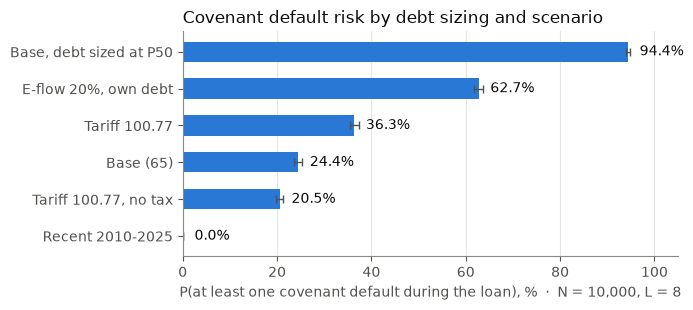

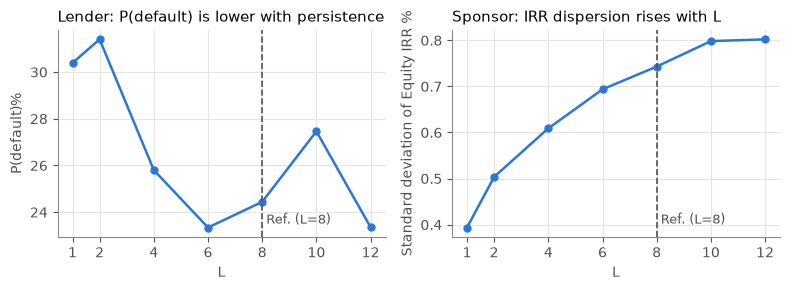

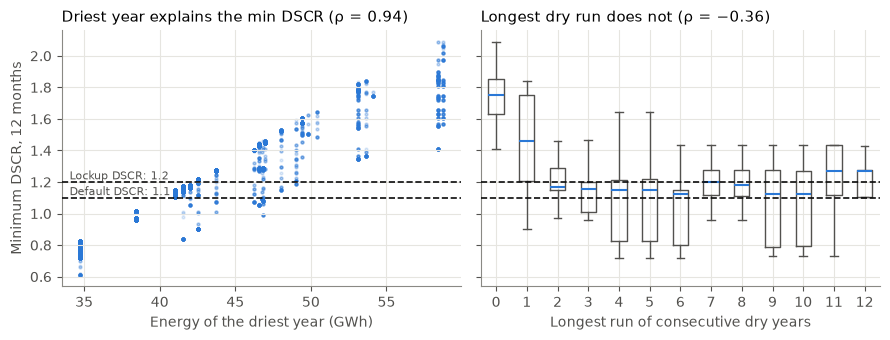

In [19]:
import matplotlib.pyplot as plt

# Shared style for all stage 3 figures
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "font.size": 10,
})
BLUE = "#2a78d6"

# Figure 1: P(default) by scenario with its 95% interval
labels = ["Base, debt sized at P50", "E-flow 20%, own debt", "Tariff 100.77", "Base (65)", "Tariff 100.77, no tax", "Recent 2010-2025"]
p = results.loc["any_default", ["Base, debt sized at P50", "E-flow 20%, own debt", "Tariff 100.77", "Base (65)",
                                "Tariff 100.77, no tax", "Recent 2010-2025, L=8",]].to_numpy()
half_ci = 1.96 * np.sqrt(p * (1 - p) / N_SIMS)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(labels, p * 100, xerr=half_ci * 100, color=BLUE, height=0.55,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
for y, v in enumerate(p):
    ax.text(v * 100 + 2.5, y, f"{v:.1%}", va="center", color="#0b0b0b")
ax.invert_yaxis()                                   # largest risk on top
ax.set_xlim(0, 105)
ax.set_xlabel("P(at least one covenant default during the loan), %  ·  N = 10,000, L = 8")
ax.grid(axis="y", visible=False)
ax.set_title("Covenant default risk by debt sizing and scenario", loc="left", color="#0b0b0b")
fig.tight_layout()
ax.set_axisbelow(True)
fig.savefig("../docs/figures/p_default_by_scenario.png", dpi=200)

# Figure 2: Two panels versus L: P(default) and equity IRR deviation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

p_by_L = sens_L.loc["any_default"]         # one value per L 
std_by_L = sens_L.loc["equity_irr_std"]    # the other panel
L_values = [1, 2, 4, 6, 8, 10, 12]         # the x axis

    # Fig.2. ax1
ax1.plot(L_values, p_by_L * 100, marker="o", color=BLUE, linewidth=1.8, markersize=5)
ax1.set_title("Lender: P(default) is lower with persistence", loc="left", fontsize=11)
ax1.set_xlabel("L")
ax1.set_ylabel("P(default)%")
ax1.set_xticks(L_values)
ax1.axvline(x=8, color="#52514e", linestyle="--", linewidth=1.2)
ax1.text(8.15, 0.05, "Ref. (L=8)", 
         transform=ax1.get_xaxis_transform(),
         color="#52514e", fontsize=9, va="bottom", ha="left")

    # Fig.2. ax2
ax2.plot(L_values, std_by_L * 100, marker="o", color=BLUE, linewidth=1.8, markersize=5)
ax2.set_title("Sponsor: IRR dispersion rises with L", loc="left", fontsize=11)
ax2.set_xlabel("L")
ax2.set_ylabel("Standard deviation of Equity IRR %")
ax2.set_xticks(L_values)
ax2.axvline(x=8, color="#52514e", linestyle="--", linewidth=1.2)
ax2.text(8.15, 0.05, "Ref. (L=8)", 
         transform=ax2.get_xaxis_transform(),
         color="#52514e", fontsize=9, va="bottom", ha="left")
fig.tight_layout()
fig.savefig("../docs/figures/h3_block_length.png", dpi=200)

# Figure 3: Two panels with one same vertical axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

    # Fig.3. ax1
ax1.scatter(sims_h1["min_annual_energy"], sims_h1["min_dscr_12m"], s=4, alpha=0.15, color=BLUE)
ax1.set_title("Driest year explains the min DSCR (ρ = 0.94)", loc="left", fontsize=11)
ax1.set_xlabel("Energy of the driest year (GWh)")
ax1.set_ylabel("Minimum DSCR, 12 months")

ax1.axhline(y=1.2, color="#0b0b0b", linestyle="--", linewidth=1.2, zorder=3)
ax1.axhline(y=1.1, color="#0b0b0b", linestyle="--", linewidth=1.2, zorder=3)

ax1.text(0.02, 1.2, "Lockup DSCR: 1.2", 
         transform=ax1.get_yaxis_transform(),
         color="#52514e", fontsize=8, va="bottom", ha="left")
ax1.text(0.02, 1.1, "Default DSCR: 1.1", 
         transform=ax1.get_yaxis_transform(),
         color="#52514e", fontsize=8, va="bottom", ha="left")

    # Fig.3. ax2
groups = [sims_h1.loc[sims_h1["longest_dry_run"] == k, "min_dscr_12m"] for k in range(13)]
ax2.boxplot(groups, positions=range(13), showfliers=False,
            medianprops = {"color": BLUE, "linewidth": 1.5},
            boxprops = {"color": "#52514e"},
            whiskerprops={"color": "#52514e"}, 
            capprops={"color": "#52514e"})
ax2.set_title("Longest dry run does not (ρ = −0.36)", loc="left", fontsize=11)
ax2.set_xlabel("Longest run of consecutive dry years")


ax2.axhline(y=1.2, color="#0b0b0b", linestyle="--", linewidth=1.2, zorder=3)
ax2.axhline(y=1.1, color="#0b0b0b", linestyle="--", linewidth=1.2, zorder=3)


fig.tight_layout()
fig.savefig("../docs/figures/h1_driest_year_vs_dry_run.png", dpi=200)